# Temporal server against the other servers in a settled room

**Question.** Once a room is learned, what does keeping a belief over time on the server (`TemporalServer`, see `cumulative_bits.ipynb` section 4) buy, compared with the servers and non-adaptive tags looked at before? This is the realistic deployment: the tag stays put, people come and go, furniture moves a little; it is not carried to a different room.

**Data.** `results/static_room/`: one room replayed 6× with state kept (`static_room.py`), FCOS as teacher, the calibrated 96-pixel online learner. Servers: `default` (TieredServer, check interval up to 64, full frame every 4 trusted thumbnails), `relaxed` (TieredServer, up to 1,024 and 16), `relaxed_anomaly` (TemporalServer with only the learned anomaly trigger), `relaxed_temporal` (TemporalServer: belief + learned trigger), and `relaxed_temporal` with true labels as teacher (the control). Non-adaptive references: FCOS on what a fixed tag sends every query (`results/teachers/`; JPEG and thumbnails exist for the Mall tile only).

Caveat: passes after the first replay identical frames, the best case for any learner. Pass 1 is a fair first deployment.

Videos of the same comparison: `results/demo/temporal_mall_p4_200-700.mp4` and `temporal_A_p4_0-500.mp4` (`temporal_video.py`).

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
sys.path.insert(0, str(Path('.').resolve()))
from semwisp import piropo
from semwisp.metrics import balanced_accuracy
from tiered_checks import fcos_cutoffs

RES = piropo.REPO / 'results'
SR, TEA = RES / 'static_room', RES / 'teachers'
# validated palette (dataviz validate_palette.js, light, all pairs): blue / orange / aqua; references in ink and gray
BLUE, ORANGE, AQUA, INK, GRAY, MUTED = '#2a78d6', '#eb6834', '#1baf7a', '#1f1e1c', '#8a8984', '#6b6a66'
SERVERS = {  # schedule: (label, color, line style)
    'fcos_default': ('tiered, default schedule', GRAY, '--'),
    'fcos_relaxed': ('tiered, relaxed schedule', ORANGE, '-'),
    'fcos_relaxed_anomaly': ('learned anomaly trigger only', AQUA, '-'),
    'fcos_relaxed_temporal': ('temporal', BLUE, '-'),
    'oracle_relaxed_temporal': ('temporal, true labels (control)', BLUE, ':')}
ROOMS = {'mall': 'Mall tile', 'A': 'room A'}

def load(path):
    z = np.load(path); n = len(z['label'])
    return pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)})

runs = {(room, s): load(SR / f'{room}_{s}.npz') for room in ROOMS for s in SERVERS}
rows = []
for (room, s), d in runs.items():
    for p, g in d.groupby('pass'):
        rows.append(dict(room=room, server=s, pass_=p, balanced_acc=balanced_accuracy(g), bytes_per_query=g.up_bytes.mean(),
                         code=12 * g.used_code.mean(), thumb=192 * g.thumbed.mean(),
                         full=g.up_bytes.mean() - 12 * g.used_code.mean() - 192 * g.thumbed.mean(),
                         full_rate=g.explored.mean(), thumb_rate=g.thumbed.mean()))
T = pd.DataFrame(rows)

# non-adaptive references on the same frames (pass 1 rows; every pass has the same frames)
pos, neg = fcos_cutoffs(); thr = (pos + neg) / 2
SEQFILE = {'mall tile': 'mall_tile'}
REF = {}
for room in ROOMS:
    base = runs[room, 'fcos_relaxed']; base = base[base['pass'] == 1][['seq', 't', 'label']]
    inputs = {'full frame': 'fcos_r50@480_s2'}
    if room == 'mall':
        inputs.update({'JPEG q88': 'fcos_r50@480_jpeg160x120q88_s2', 'JPEG q50': 'fcos_r50@480_jpeg160x120q50_s2',
                       'thumbnail 80×60': 'fcos_r50@480_thumb80x60_s2', 'thumbnail 40×30': 'fcos_r50@480_thumb40x30_s2'})
    for name, folder in inputs.items():
        parts = []
        for s in base.seq.unique():
            r = np.load(TEA / folder / f"{SEQFILE.get(s, s)}.npz")
            parts.append(pd.DataFrame({'seq': s, 't': r['t'], 'score': r['score'],
                                       'up_bytes': r['bytes'] if 'bytes' in r.files else np.full(len(r['t']), 19200)}))
        d = base.merge(pd.concat(parts), on=['seq', 't'], how='left', validate='1:1')
        assert d.score.notna().all(), (room, name)
        d['answer'] = (d.score >= thr).astype(int)
        REF[room, name] = (balanced_accuracy(d), d.up_bytes.mean())
pd.DataFrame([dict(room=r, input=n, balanced_acc=a, bytes_per_query=b) for (r, n), (a, b) in REF.items()])\
  .style.format({'balanced_acc': '{:.3f}', 'bytes_per_query': '{:,.0f}'}).hide(axis='index')

room,input,balanced_acc,bytes_per_query
mall,full frame,0.956,"19,200"
mall,JPEG q88,0.957,"2,874"
mall,JPEG q50,0.966,"1,118"
mall,thumbnail 80×60,0.956,"4,800"
mall,thumbnail 40×30,0.679,"1,200"
A,full frame,0.910,"19,200"


## 1. Pass by pass

Top: balanced accuracy; bottom: uplink bytes per query (log). Two charts on one x axis rather than one chart with two y scales. Dashed black: FCOS on the full frame every query (19,200 B); dotted gray (Mall tile): JPEG q88 every query.

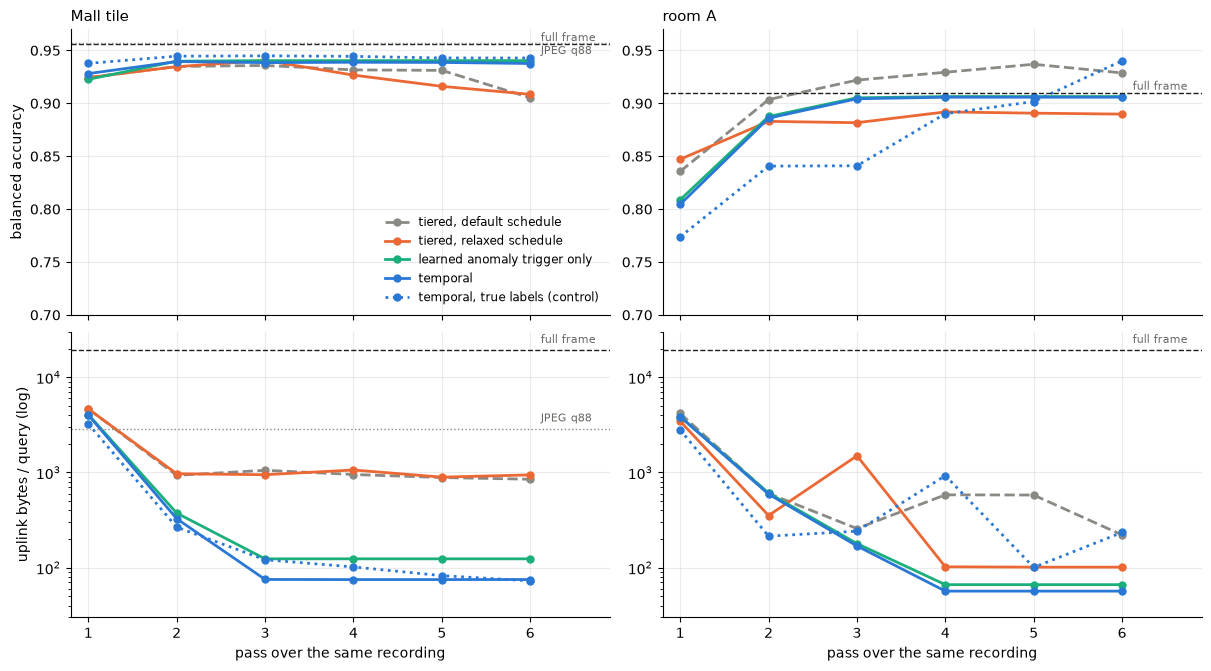

In [2]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6.6), sharex=True, constrained_layout=True)
for j, room in enumerate(ROOMS):
    for s, (lab, c, ls) in SERVERS.items():
        g = T[(T.room == room) & (T.server == s)]
        for i, col in enumerate(('balanced_acc', 'bytes_per_query')):
            axs[i, j].plot(g.pass_, g[col], color=c, ls=ls, lw=2, marker='o', ms=5, label=lab)
    for name, ls, c in (('full frame', '--', INK), ('JPEG q88', ':', GRAY)):
        if (room, name) in REF:
            a, b = REF[room, name]
            axs[0, j].axhline(a, color=c, ls=ls, lw=1); axs[1, j].axhline(b, color=c, ls=ls, lw=1)
            off = -0.008 if name == 'JPEG q88' else 0.006           # full frame and JPEG q88 nearly coincide
            axs[0, j].text(6.12, a + off, name, va='center', fontsize=8, color=MUTED)
            axs[1, j].text(6.12, b * 1.12, name, va='bottom', fontsize=8, color=MUTED)
    axs[0, j].set_title(ROOMS[room], loc='left', fontsize=11)
    axs[1, j].set_yscale('log'); axs[1, j].set_ylim(30, 30000)
    axs[1, j].set_xlabel('pass over the same recording'); axs[1, j].set_xticks(range(1, 7)); axs[1, j].set_xlim(0.8, 6.9)
    for ax in axs[:, j]:
        ax.grid(alpha=0.25)
        for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
axs[0, 0].set_ylabel('balanced accuracy'); axs[1, 0].set_ylabel('uplink bytes / query (log)')
axs[0, 0].set_ylim(0.7, 0.97); axs[0, 1].set_ylim(0.7, 0.97)
axs[0, 0].legend(frameon=False, fontsize=8.5, loc='lower right')
plt.show()

## 2. Accuracy against bytes

Each adaptive server is a path from pass 1 (small marker) to pass 6 (large marker). Non-adaptive tags are single points (black squares): they cost the same on every pass. Up and to the left is better. Labels give pass 6 for the tiered (relaxed) and temporal servers. Off the Mall chart: thumbnail 40×30, 0.68 at 1,200 B.

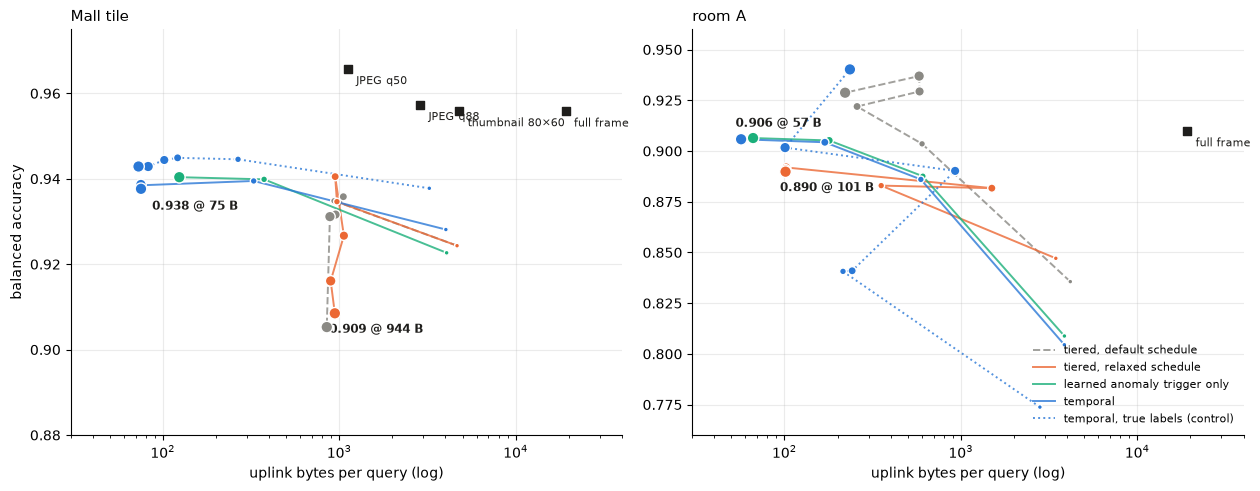

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)
for ax, room in zip(axs, ROOMS):
    for (r, name), (a, b) in REF.items():
        if r == room and a > 0.8:
            ax.scatter(b, a, marker='s', s=40, color=INK, zorder=3)
            ax.annotate(name, (b, a), xytext=(6, -11), textcoords='offset points', fontsize=8, color=INK)
    for s, (lab, c, ls) in SERVERS.items():
        g = T[(T.room == room) & (T.server == s)].sort_values('pass_')
        ax.plot(g.bytes_per_query, g.balanced_acc, color=c, ls=ls, lw=1.4, alpha=0.8, label=lab)
        ax.scatter(g.bytes_per_query, g.balanced_acc, s=np.linspace(12, 70, len(g)), color=c, edgecolor='white', linewidth=1, zorder=4)
        last = g.iloc[-1]
        if s in ('fcos_relaxed', 'fcos_relaxed_temporal'):
            ax.annotate(f'{last.balanced_acc:.3f} @ {last.bytes_per_query:,.0f} B', (last.bytes_per_query, last.balanced_acc),
                        xytext=((8, -15) if room == 'mall' else (-4, 9)) if s.endswith('temporal') else (-4, -14), textcoords='offset points', fontsize=8.5,
                        color=INK, ha='left', fontweight='bold')
    ax.set_xscale('log'); ax.set_xlim(30, 40000)
    ax.set_title(ROOMS[room], loc='left', fontsize=11)
    ax.set_xlabel('uplink bytes per query (log)'); ax.grid(alpha=0.25)
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
axs[0].set_ylabel('balanced accuracy')
axs[0].set_ylim(0.88, 0.975); axs[1].set_ylim(0.76, 0.96)
axs[1].legend(frameon=False, fontsize=8, loc='lower right')
plt.show()

## 3. Where the bytes go (last pass)

Mean uplink per query split by what was sent: the 12-byte code, 16×12 thumbnails (192 B), full frames (19,200 B). One blue ramp, light to dark in order of size.

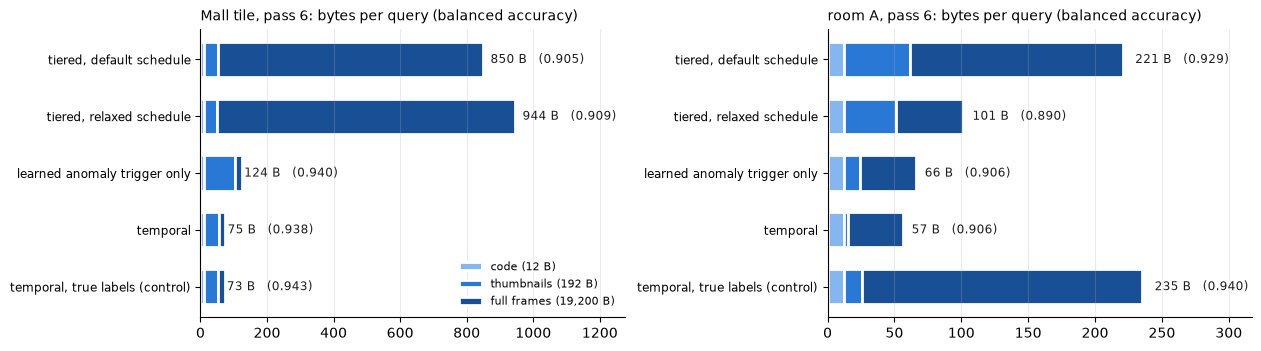

In [4]:
PARTS = [('code', '#86b6ef', 'code (12 B)'), ('thumb', '#2a78d6', 'thumbnails (192 B)'), ('full', '#184f95', 'full frames (19,200 B)')]
last = T[T.pass_ == T.pass_.max()]
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.4), constrained_layout=True)
for ax, room in zip(axs, ROOMS):
    g = last[last.room == room].set_index('server').loc[list(SERVERS)]
    y = np.arange(len(g))[::-1]
    left = np.zeros(len(g))
    for col, c, lab in PARTS:
        ax.barh(y, g[col], left=left, color=c, height=0.62, edgecolor='white', linewidth=2, label=lab)
        left += g[col].values
    for yi, (tot, acc) in zip(y, zip(g.bytes_per_query, g.balanced_acc)):
        ax.text(tot * 1.02 + 5, yi, f'{tot:,.0f} B   ({acc:.3f})', va='center', fontsize=8.5, color=INK)
    ax.set_yticks(y, [SERVERS[s][0] for s in g.index], fontsize=8.5)
    ax.set_title(f'{ROOMS[room]}, pass 6: bytes per query (balanced accuracy)', loc='left', fontsize=10)
    ax.set_xlim(0, g.bytes_per_query.max() * 1.35)
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
    ax.grid(alpha=0.25, axis='x')
axs[0].legend(frameon=False, fontsize=8, loc='lower right')
plt.show()
last.set_index(['room', 'server'])[['balanced_acc', 'bytes_per_query', 'code', 'thumb', 'full', 'full_rate', 'thumb_rate']]\
  .style.format('{:.3f}').format('{:,.1f}', subset=['bytes_per_query', 'code', 'thumb', 'full'])

## 4. Close-up: 200 queries of the Mall tile, settled (pass 4)

Rows: the truth, each server's answer (dark = person), and the temporal server's belief P(person) as a line. Markers show what each server fetched beyond the code: ○ thumbnail, ● full frame. Below: bytes per query (log).

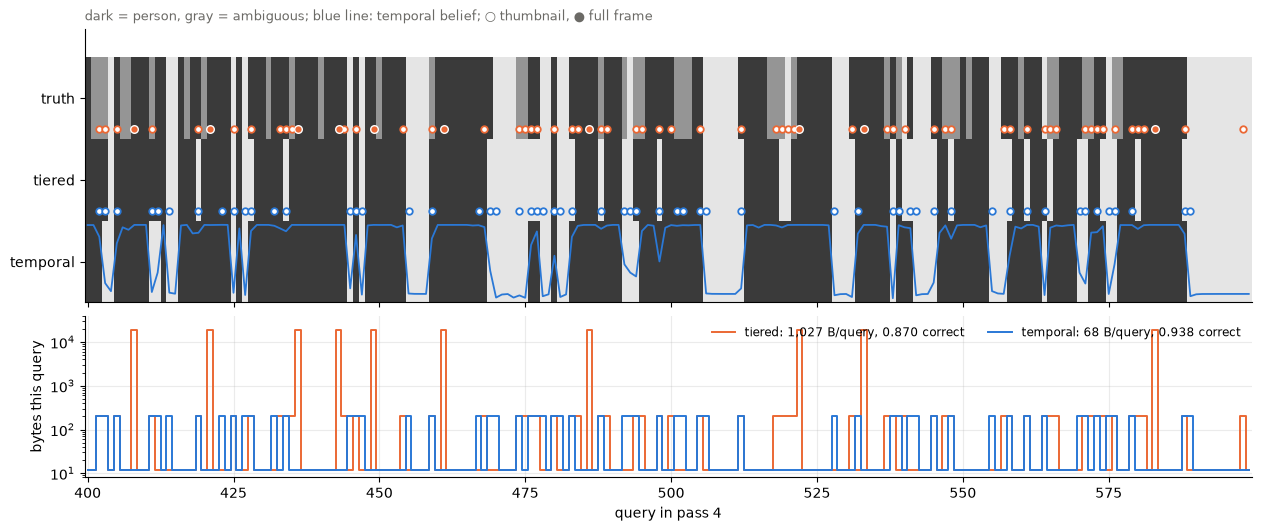

In [5]:
room, p, a, b = 'mall', 4, 400, 600
A = runs[room, 'fcos_relaxed']; A = A[A['pass'] == p].reset_index(drop=True).iloc[a:b]
B = runs[room, 'fcos_relaxed_temporal']; B = B[B['pass'] == p].reset_index(drop=True).iloc[a:b]
q = np.arange(a, b)
fig, (ax, axb) = plt.subplots(2, 1, figsize=(12.5, 5.2), sharex=True, gridspec_kw=dict(height_ratios=[2.2, 1.3]), constrained_layout=True)
lab = A.label.values.astype(float); lab[lab < 0] = 0.5
R = np.vstack([lab, A.answer.values, B.answer.values])
ax.imshow(R, aspect='auto', cmap='Greys', vmin=-0.3, vmax=1.3, interpolation='nearest', extent=(a - 0.5, b - 0.5, 2.5, -0.5))
ax.plot(q, 2.45 - 0.9 * B.belief.values, color=BLUE, lw=1.3)
for row, d, c in ((1, A, ORANGE), (2, B, BLUE)):
    th, fu = d.thumbed.astype(bool).values & ~d.explored.astype(bool).values, d.explored.astype(bool).values
    ax.scatter(q[th], np.full(th.sum(), row - 0.62), marker='o', s=22, facecolor='white', edgecolor=c, linewidth=1.3, zorder=3)
    ax.scatter(q[fu], np.full(fu.sum(), row - 0.62), marker='o', s=30, color=c, edgecolor='white', linewidth=1, zorder=4)
ax.set_yticks([0, 1, 2], ['truth', 'tiered', 'temporal'])
ax.set_ylim(2.5, -0.85)
ax.set_title('dark = person, gray = ambiguous; blue line: temporal belief; ○ thumbnail, ● full frame', loc='left', fontsize=9.5, color=MUTED)
for d, c, l in ((A, ORANGE, 'tiered'), (B, BLUE, 'temporal')):
    axb.step(q, d.up_bytes.values, where='mid', color=c, lw=1.4, label=f'{l}: {d.up_bytes.mean():,.0f} B/query, '
             f'{(d.answer == d.label)[d.label >= 0].mean():.3f} correct')
axb.set_yscale('log'); axb.set_ylim(8, 40000); axb.set_ylabel('bytes this query')
axb.set_xlabel(f'query in pass {p}'); axb.legend(frameon=False, fontsize=8.5, loc='upper right', ncol=2)
for x in (ax, axb):
    for sp in ('top', 'right'): x.spines[sp].set_visible(False)
axb.grid(alpha=0.25)
plt.show()

## Findings

* **Mall tile: the temporal server is the cheapest and among the most accurate adaptive servers.** Pass 6: 0.938 at 75 B/query, against 0.909 at 944 (tiered, relaxed) and 0.905 at 850 (tiered, default). True labels give 0.943 at 73 B, so with FCOS it is within 0.005 of the control. The tiered servers lose accuracy over identical passes (0.935 → 0.909); the temporal server holds 0.938–0.939 from pass 2.
* **Where the bytes went** (section 3): almost all of the tiered servers' Mall uplink is full frames fetched by the fixed anomaly trigger on ordinary person events. The learned trigger removes them (124 B); the belief then halves the thumbnails (75 B). What is left is the code (12 B) plus thumbnails on uncertain queries.
* **Against non-adaptive tags (Mall tile):** full frame 0.956 at 19,200 B, JPEG q88 0.957 at 2,874 B, JPEG q50 0.966 at 1,118 B, 80×60 thumbnail 0.956 at 4,800 B. The settled temporal server is 0.02–0.03 below them at **15× fewer bytes than JPEG q50 and 38× fewer than JPEG q88**. (The Mall tile's people are large, so even small JPEGs work well here.)
* **Room A:** temporal 0.906 at 57 B/query against 0.890 at 101 (relaxed); full-frame FCOS is 0.910. The `default` tiered schedule is more accurate (0.929) at 4× the bytes (221 B), and true labels reach 0.940 at 235 B. So in room A the temporal server buys bytes, not accuracy: with the relaxed schedule the code is checked rarely and stays at full-frame-FCOS accuracy.
* **Close-up** (section 4, Mall pass 4, queries 400–599): tiered 0.870 correct at 1,027 B/query, temporal 0.938 at 68 B. The tiered server's answer flickers with single noisy code replies, and each person entering sets enough bits to trigger a full frame; the belief rides through both.
* Pass 1 (first deployment) is about the same for all servers: 0.92–0.94 at 3.2–4.7 kB in the Mall, 0.77–0.85 at 2.8–4.4 kB in room A. The temporal server's gain is in the settled phase, which is the realistic one for a tag that stays put.